Q1. Camera 5x5 = 25 points


(a) In the Assignment 1, Q1, find the coordinates of the centre of the swinging load,
𝑜1(𝑥, 𝑦, 𝑧) for all frames in training set rgb_train_val_swingingload.avi. Use the 𝑀𝑖𝑛𝑡
obtained in the Lab. Plot the 3D coordinates of swinging load for all frames.

Number of npy files: 900

0: 480x640 1 box, 193.6ms
Speed: 8.5ms preprocess, 193.6ms inference, 9.7ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 58.6ms
Speed: 3.3ms preprocess, 58.6ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 43.9ms
Speed: 1.4ms preprocess, 43.9ms inference, 1.7ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 39.2ms
Speed: 2.3ms preprocess, 39.2ms inference, 0.6ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 45.4ms
Speed: 1.2ms preprocess, 45.4ms inference, 1.0ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 85.8ms
Speed: 7.0ms preprocess, 85.8ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 43.3ms
Speed: 2.1ms preprocess, 43.3ms inference, 1.0ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 46.2ms
Speed: 1.3ms preprocess, 46.2ms inference, 1.0ms postprocess per image at shape (1, 3,

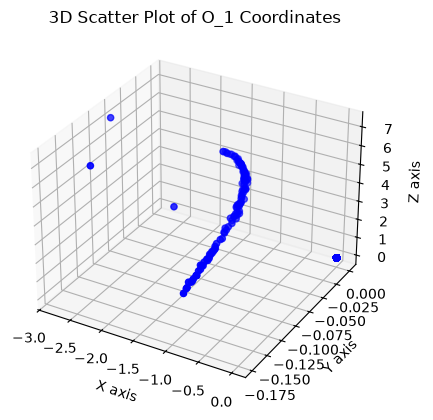

In [21]:
# Prep - Retrieve video and model from q1/data/train and q1/model

import glob
import json
import os
import cv2
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt

model = YOLO("../assignment_1/q1/model/YOLO_swinging_load.pt")
video = "../assignment_1/q1/data/train/color_video/color_video.avi"

cap = cv2.VideoCapture(video)
if not cap.isOpened():
    print("Error: Cannot open video file!")
    exit()

npy_files = sorted(glob.glob("../assignment_1/q1/data/train/depth_raw/*.npy"))
print(f"Number of npy files: {len(npy_files)}")

depth_scale_json_file = "../assignment_1/q1/data/train/depth_scale_json/depth_scale.json"
with open(depth_scale_json_file, 'r') as f:
    depth_scale = json.load(f)["depth_scale"]

center_coords = []

# Open video, store 3D center coordinates in center_coords[]

idx = 0
while cap.isOpened() and idx < len(npy_files):
    ret, frame = cap.read()
    if not ret:
        print("Video frame is empty or video has played till completion")
        break
    
    results = model(frame)
    cx,cy = results[0].boxes.xywh[0,:2].cpu().numpy().astype(int)  
    
    # Find depth at center point
    depth_file = np.load(npy_files[idx]) 
    idx += 1
    depth = np.mean(depth_file[cy, cx]) * depth_scale 
    
    center = np.array([
        [cx],
        [cy],
        [depth]
    ])

    center_coords.append(center)

cap.release()
cv2.destroyAllWindows()

# A - Use intrinsic matrix From Lab 3 to convert center points to 3D  coordinates relative to camera, store in O_1_coords[]

M_int = np.array([
    [1.72992620e+03, 0.00000000e+00, 1.06974682e+03],
    [0.00000000e+00, 2.66589388e+03, 2.59554251e+02],
    [0.00000000e+00, 0.00000000e+00, 1.00000000e+00]
])

O_1_coords = []

for center in center_coords :
    pixel_coords = np.array([[center[0][0]], [center[1][0]], [1]])
    camera_coords = np.linalg.inv(M_int) @ pixel_coords * center[2][0]
    O_1_coords.append(camera_coords)
    print("Camera Coordinates:", camera_coords.flatten())

# Plot all O_1_coords in 3D space using matplotlib as blue points
O_1_coords = np.array(O_1_coords).squeeze()  # Convert list of arrays to a single 2D array
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(O_1_coords[:, 0], O_1_coords[:, 1], O_1_coords[:, 2], c='b', marker='o')
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_zlabel('Z axis')
plt.title('3D Scatter Plot of O_1 Coordinates')
plt.show()

(b) Say, the default intrinsic matrix of L515 is

$$M_d = \begin{bmatrix} 1342 & 0 & 325 \\  0 & 1342 & 235 \\  0 & 0 & 1 \end{bmatrix}$$

Use this matrix to find the 3D coordinates of the center of swinging load for all frames ($o_2$) and plot them.

Number of npy files: 900

0: 480x640 1 box, 60.6ms
Speed: 2.3ms preprocess, 60.6ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 54.8ms
Speed: 1.8ms preprocess, 54.8ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 50.2ms
Speed: 1.4ms preprocess, 50.2ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 51.4ms
Speed: 1.3ms preprocess, 51.4ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 45.6ms
Speed: 1.2ms preprocess, 45.6ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 51.3ms
Speed: 1.1ms preprocess, 51.3ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 46.9ms
Speed: 1.2ms preprocess, 46.9ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 49.4ms
Speed: 1.1ms preprocess, 49.4ms inference, 0.6ms postprocess per image at shape (1, 3, 4

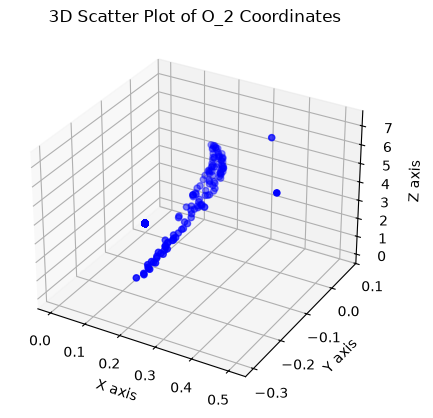

In [4]:
# Q1 B, copy code from above, but use standard matrix to convert center points to 3D world coordinates relative to camera, store in O_2_coords[]

# Prep - Retrieve video and model from q1/data/train and q1/model

import glob
import json
import os
import cv2
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt

model = YOLO("../assignment_1/q1/model/YOLO_swinging_load.pt")
video = "../assignment_1/q1/data/train/color_video/color_video.avi"

cap = cv2.VideoCapture(video)
if not cap.isOpened():
    print("Error: Cannot open video file!")
    exit()

npy_files = sorted(glob.glob("../assignment_1/q1/data/train/depth_raw/*.npy"))
print(f"Number of npy files: {len(npy_files)}")

depth_scale_json_file = "../assignment_1/q1/data/train/depth_scale_json/depth_scale.json"
with open(depth_scale_json_file, 'r') as f:
    depth_scale = json.load(f)["depth_scale"]

center_coords = []

# Open video, store 3D center coordinates in center_coords[]

idx = 0
while cap.isOpened() and idx < len(npy_files):
    ret, frame = cap.read()
    if not ret:
        print("Video frame is empty or video has played till completion")
        break
    
    results = model(frame)
    cx,cy = results[0].boxes.xywh[0,:2].cpu().numpy().astype(int)  
    
    # Find depth at center point
    depth_file = np.load(npy_files[idx]) 
    idx += 1
    depth = np.mean(depth_file[cy, cx]) * depth_scale 
    
    center = np.array([
        [cx],
        [cy],
        [depth]
    ])

    center_coords.append(center)

cap.release()
cv2.destroyAllWindows()

# B - Use given matrix to convert center points to 3D coordinates relative to camera, store in O_2_coords[]

M_int = np.array([
    [1.342e+03, 0.00e+00, 3.25e+02],
    [0.00e+00, 1.342e+03, 2.35e+02],
    [0.00e+00, 0.00e+00, 1.00e+00]
])

O_2_coords = []

for center in center_coords :
    pixel_coords = np.array([[center[0][0]], [center[1][0]], [1]])
    camera_coords = np.linalg.inv(M_int) @ pixel_coords * center[2][0]
    O_2_coords.append(camera_coords)
    print("Camera Coordinates:", camera_coords.flatten())

# Plot all O_2_coords in 3D space using matplotlib as blue points
O_2_coords = np.array(O_2_coords).squeeze()  # Convert list of arrays to a single 2D array
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(O_2_coords[:, 0], O_2_coords[:, 1], O_2_coords[:, 2], c='b', marker='o')
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_zlabel('Z axis')
plt.title('3D Scatter Plot of O_2 Coordinates')
plt.show()

(c) Which intrinsic matrix — $M_{\text{int}}$ or $M_d$, is accurate? Give reasons for your answer.

Clearly the calculated intrinsic matrix is horribly incorrect and not accurate (it says load is left, while its actually right), while the default matrix is much more accurate.


(d) From the data set obtained from (a) and (b) i.e. 𝑜1 𝑎𝑛𝑑 𝑜2. Implement ML model that
learns the function parameters such that 𝑓𝜃(𝑜1) = 𝑜2∗. Explain the results by
finding/demonstrating the relevant KPIs.

In [ ]:
# Blank

(e) Find the Euclidean error between (i) 𝑜1 𝑎𝑛𝑑 𝑜2 and (ii) 𝑜1 𝑎𝑛𝑑 𝑜2∗. Make the
interpretations of the results that you obtain

Mean Euclidean Error (MEE) between O_1_coords and O_2_coords: 0.2107 meters
Root Mean Square Error (RMSE) between O_1_coords and O_2_coords: 0.5683 meters


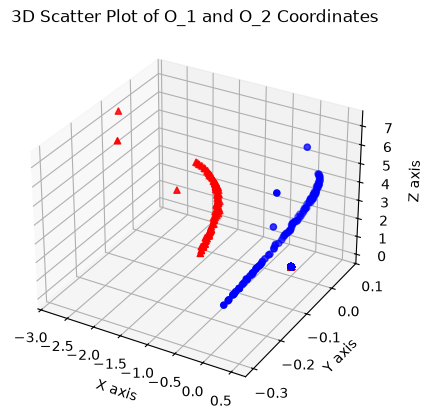

In [ ]:
# Q1 E (i)

# Mean Euclidean Error (MEE) between O_1_coords and O_2_coords
import numpy as np

errors = np.linalg.norm(O_2_coords - O_1_coords, axis=1)
mean_error = np.mean(errors)
print(f"Mean Euclidean Error (MEE) between O_1_coords and O_2_coords: {mean_error:.4f} meters")

errors_2 = errors**2
rmse = np.sqrt(np.mean(errors_2))
print(f"Root Mean Square Error (RMSE) between O_1_coords and O_2_coords: {rmse:.4f} meters")

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(O_2_coords[:, 0], O_2_coords[:, 1], O_2_coords[:, 2], c='b', marker='o')
ax.scatter(O_1_coords[:, 0], O_1_coords[:, 1], O_1_coords[:, 2], c='r', marker='^')
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_zlabel('Z axis')
plt.title('3D Scatter Plot of O_1 and O_2 Coordinates')
plt.show()


Q2. Lidar 10+15 = 25 points

(a) Use Ouster lidar in Lab to record the trajectory of swinging load. Find the center
of swinging load for all frames, and plot them. 

In [ ]:
# Prep, get lidar data from pcap file within angles

pcap_file = "../lab_4/lidar-pcd processing-2026 class/swinging_load.pcap" 
json_file = "../lab_4/lidar-pcd processing-2026 class/swinging_load.json"

min_angle = 180
max_angle = 270

# Store lidar data within angles in a list of numpy arrays, each array is a point cloud for a single packet
point_clouds = []



Successfully extracted 101 frames to q2/a/images/


(b) Leverage KISS ICP to find the pose of center of load in consecutive lidar frame.